In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

DATA_PATH = "../data/CXR Reports/cxr_df.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Shape: (91685, 4)

Columns:
['Unnamed: 0', 'id', 'text', 'path']


,Unnamed: 0,id,text,path
0,0,s50260386,A tip of a left Port-A-Cath lies in the low su...,../input/curated-cxr-report-generation-dataset...
1,1,s58019009,"AP chest compared to ___, 9:04 a.m.: In place ...",../input/curated-cxr-report-generation-dataset...
2,2,s54123565,"AP chest compared to ___, read in conjunction ...",../input/curated-cxr-report-generation-dataset...
3,3,s51811896,A tracheostomy cannula is located within the u...,../input/curated-cxr-report-generation-dataset...
4,4,s59641633,Bilateral previous mentioned reticular opaciti...,../input/curated-cxr-report-generation-dataset...


In [2]:
FINDINGS = {
    "Pneumonia": [
        "pneumonia"
    ],

    "Pleural Effusion": [
        "pleural effusion",
        "pleural fluid",
        "effusions"
    ],

    "Pneumothorax": [
        "pneumothorax",
        "pneumothoraces"
    ],

    "Atelectasis": [
        "atelectasis"
    ],

    "Consolidation": [
        "consolidation"
    ],

    "Pulmonary Edema": [
        "pulmonary edema",
        "pulmonary oedema"
    ],

    "Cardiomegaly": [
        "cardiomegaly",
        "enlarged cardiac silhouette",
        "enlarged heart"
    ],

    "Opacity": [
        "opacity",
        "opacities",
        "opacification"
    ],

    "Nodule": [
        "nodule",
        "nodular"
    ],

    "Mass": [
        "mass",
        "mass-like"
    ],

    "Fracture": [
        "fracture",
        "fractures"
    ],

    "Emphysema": [
        "emphysema"
    ],

    "Fibrosis": [
        "fibrosis",
        "fibrotic"
    ],

    "Pleural Thickening": [
        "pleural thickening"
    ]
}

In [3]:
text = df["text"].fillna("").str.lower()

counts = {}

for finding, terms in FINDINGS.items():
    pattern = "|".join(re.escape(term) for term in terms)

    counts[finding] = text.str.contains(
        pattern,
        regex=True,
        na=False
    ).sum()

finding_counts = (
    pd.Series(counts)
    .sort_values(ascending=False)
)

print(finding_counts)

Pleural Effusion      58379
Pneumothorax          52374
Opacity               33535
Atelectasis           32748
Pulmonary Edema       25172
Consolidation         18648
Pneumonia             16832
Cardiomegaly          15794
Fracture               3539
Emphysema              2391
Nodule                 2141
Mass                   2059
Pleural Thickening      860
Fibrosis                506
dtype: int64


In [4]:
# Percentage of reports mentioning each finding
finding_percentage = (
    finding_counts / len(df) * 100
).round(2)

summary = pd.DataFrame({
    "Count": finding_counts,
    "Percentage": finding_percentage
})

print(summary)

                    Count  Percentage
Pleural Effusion    58379       63.67
Pneumothorax        52374       57.12
Opacity             33535       36.58
Atelectasis         32748       35.72
Pulmonary Edema     25172       27.45
Consolidation       18648       20.34
Pneumonia           16832       18.36
Cardiomegaly        15794       17.23
Fracture             3539        3.86
Emphysema            2391        2.61
Nodule               2141        2.34
Mass                 2059        2.25
Pleural Thickening    860        0.94
Fibrosis              506        0.55


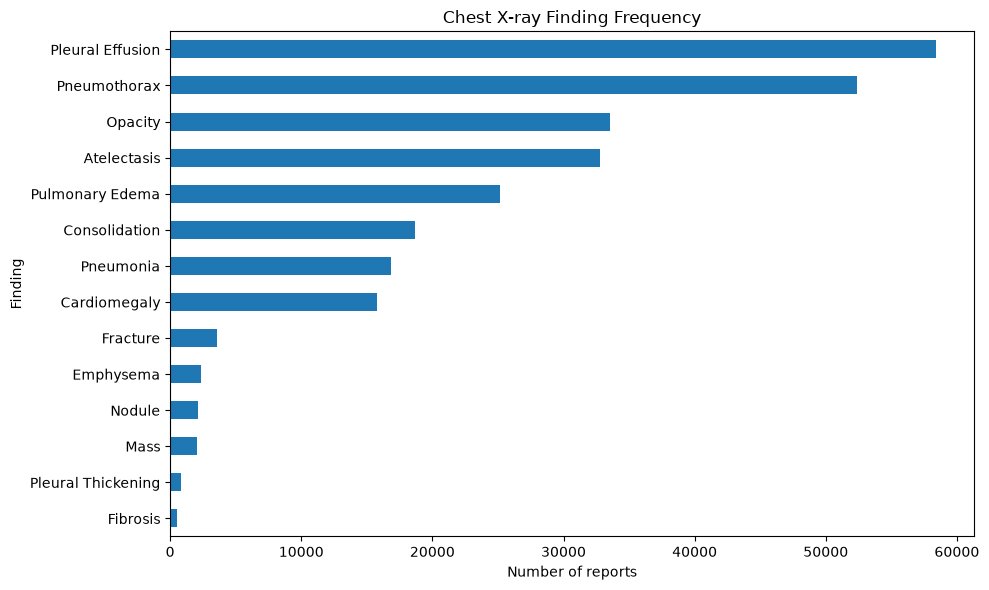

In [5]:
plt.figure(figsize=(10, 6))

finding_counts.sort_values().plot(kind="barh")

plt.xlabel("Number of reports")
plt.ylabel("Finding")
plt.title("Chest X-ray Finding Frequency")
plt.tight_layout()

plt.show()

In [21]:
def classify_finding(text, terms):
    """
    Returns:
        1  -> positive
        0  -> explicitly negative
        -1 -> uncertain
        None -> not mentioned
    """

    if not isinstance(text, str):
        return None

    text = text.lower()

    sentences = re.split(r'(?<=[.!?])\s+', text)

    for sentence in sentences:

        # Check whether the finding is mentioned
        matched = any(
            re.search(
                r'\b' + re.escape(term) + r'\b',
                sentence
            )
            for term in terms
        )

        if not matched:
            continue

        # -------------------------
        # UNCERTAIN
        # -------------------------
        uncertainty_patterns = [
            r'\bpossible\b',
            r'\bpossibly\b',
            r'\bmay represent\b',
            r'\bmay be\b',
            r'\bmay develop\b',
            r'\bmay be developing\b',
            r'\bcannot exclude\b',
            r'\bcannot be excluded\b',
            r'\bquestion of\b',
            r'\bsuspicious for\b',
            r'\bsuggestive of\b',
            r'\bconsistent with\b.*\bpossible\b',
            r'\bcoexisting\b.*\bpossible\b',
        ]

        if any(
            re.search(pattern, sentence)
            for pattern in uncertainty_patterns
        ):
            return -1

        # -------------------------
        # NEGATIVE
        # -------------------------
        negative_patterns = [
            r'\bno evidence of\b',
            r'\bno\b',
            r'\bwithout\b',
            r'\bnegative for\b',
            r'\babsence of\b',
            r'\babsent\b',
            r'\bnot seen\b',
            r'\bnot identified\b',
            r'\bthere is no\b',
            r'\bthere are no\b',
            r'\bno clear evidence of\b',
        ]

        if any(
            re.search(pattern, sentence)
            for pattern in negative_patterns
        ):
            return 0

        # -------------------------
        # POSITIVE
        # -------------------------
        return 1

    return None

In [22]:
NEGATION_PHRASES = [
    "no evidence of",
    "no",
    "without",
    "negative for",
    "absence of",
    "absent",
    "not seen",
    "not identified",
    "there is no",
    "there are no"
]

UNCERTAIN_PHRASES = [
    "possible",
    "possibly",
    "may represent",
    "cannot exclude",
    "cannot be excluded",
    "question of",
    "suspicious for",
    "suggestive of",
    "likely"
]

In [23]:
test_reports = [
    "No evidence of pneumothorax.",
    "There is a small right pneumothorax.",
    "Possible pneumothorax cannot be excluded.",
    "No pleural effusion.",
    "Small bilateral pleural effusions are present.",
    "Coexisting pneumonia is possible given clinical history.",
    "New basal consolidation suggesting pneumonia may be developing."
]

for report in test_reports:

    if "pneumonia" in report.lower():
        finding = "Pneumonia"
    elif "pleural" in report.lower():
        finding = "Pleural Effusion"
    else:
        finding = "Pneumothorax"

    result = classify_finding(
        report,
        FINDINGS[finding]
    )

    print(result, "->", report)

0 -> No evidence of pneumothorax.
1 -> There is a small right pneumothorax.
-1 -> Possible pneumothorax cannot be excluded.
0 -> No pleural effusion.
1 -> Small bilateral pleural effusions are present.
-1 -> Coexisting pneumonia is possible given clinical history.
-1 -> New basal consolidation suggesting pneumonia may be developing.


In [24]:
for finding in ["Pneumonia", "Pleural Effusion", "Pneumothorax"]:

    print("\n" + "=" * 70)
    print(finding)
    print("=" * 70)

    terms = FINDINGS[finding]

    count = 0

    for _, row in df.iterrows():

        result = classify_finding(row["text"], terms)

        if result is not None:

            print(f"\nLabel: {result}")
            print(row["text"][:500])

            count += 1

        if count >= 5:
            break


Pneumonia

Label: -1
AP chest compared to ___, 9:04 a.m.: In place of right lower lobe atelectasis, is now new basal consolidation suggesting pneumonia may be developing where previously there was bronchial obstruction due to aspiration. Heart size normal. Lungs otherwise clear. No pleural abnormality. ET tube in standard placement. Nasogastric tube ends in the stomach. No pneumothorax.

Label: 1
AP chest radiograph. There is slight worsening opacification in the right mid lung consistent with pneumonia in the background setting of known multifocal bronchioalveolar carcinoma. The cardiomediastinal silhouette is stable. There is no pulmonary vascular engorgement, large pleural effusion, or pneumothorax.

Label: 0
Compared to prior chest radiographs ___ through ___. There is no clear evidence of aspiration or pneumonia. Heart size is normal but along with mediastinal venous caliber, increased since ___. Pleural effusions are small if any. No pneumothorax. Left PIC line ends in the left 

In [25]:
for finding, terms in FINDINGS.items():
    df[f"label_{finding}"] = df["text"].fillna("").apply(
        lambda x: classify_finding(x, terms)
    )

In [27]:
label_columns = [
    col for col in df.columns
    if col.startswith("label_")
]

label_summary = {}

for col in label_columns:
    counts = df[col].value_counts(dropna=False)

    label_summary[col.replace("label_", "")] = {
        "Positive": counts.get(1.0, 0),
        "Negative": counts.get(0.0, 0),
        "Uncertain": counts.get(-1.0, 0),
        "Not Mentioned": counts.get(np.nan, 0)
    }

label_summary_df = pd.DataFrame(label_summary).T

label_summary_df

,Positive,Negative,Uncertain,Not Mentioned
Pneumonia,7595,7499,1718,74873
Pleural Effusion,31347,24601,2425,33312
Pneumothorax,5149,46717,373,39446
Atelectasis,28922,1206,2618,58939
Consolidation,6719,9083,844,75039
Pulmonary Edema,13579,10711,880,66515
Cardiomegaly,14613,1028,153,75891
Opacity,27007,2479,3105,59094
Nodule,1116,59,127,90383
Mass,1227,75,83,90300


In [28]:
label_summary_df["Usable"] = (
    label_summary_df["Positive"] +
    label_summary_df["Negative"]
)

label_summary_df["Positive % of Mentioned"] = (
    label_summary_df["Positive"] /
    (
        label_summary_df["Positive"] +
        label_summary_df["Negative"] +
        label_summary_df["Uncertain"]
    ) * 100
).round(2)

label_summary_df

,Positive,Negative,Uncertain,Not Mentioned,Usable,Positive % of Mentioned
Pneumonia,7595,7499,1718,74873,15094,45.18
Pleural Effusion,31347,24601,2425,33312,55948,53.70
Pneumothorax,5149,46717,373,39446,51866,9.86
Atelectasis,28922,1206,2618,58939,30128,88.32
Consolidation,6719,9083,844,75039,15802,40.36
Pulmonary Edema,13579,10711,880,66515,24290,53.95
Cardiomegaly,14613,1028,153,75891,15641,92.52
Opacity,27007,2479,3105,59094,29486,82.87
Nodule,1116,59,127,90383,1175,85.71
Mass,1227,75,83,90300,1302,88.59


In [29]:
import os

path_exists = df["path"].apply(os.path.exists)

print("Total rows:", len(df))
print("Images found:", path_exists.sum())
print("Images missing:", (~path_exists).sum())
print("Image availability:", round(path_exists.mean() * 100, 2), "%")

Total rows: 91685
Images found: 0
Images missing: 91685
Image availability: 0.0 %


In [30]:
print(df.loc[~path_exists, "path"].head(10).tolist())

['../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s50260386.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s58019009.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s54123565.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s51811896.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s59641633.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s54057351.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s53028287.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s51844541.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s50939248.jpg', '../input/curated-cxr-report-generation-dataset/mimic_dset/re_512_3ch/Train/s55777915.jpg']
